<div dir="rtl" style="text-align: right">

# Data Preparation

</div>

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../OnlineRetail.csv")

print(df.head())
print(f"\nrows & columns: {df.shape}\n")
print(f"columns list:   {df.columns.tolist()}")

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

rows & columns: (541909, 8)

columns list:   ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


<div dir="rtl" style="text-align: right">

--- 

## بخش ۱: Data Selection

### Question 3
بر اساس تحلیل مرحله قبل، کدام ستون‌ها بیشترین ارتباط را با رفتار خرید و ریزش دارند؟ فهرستشان را استخراج کنید.

**چرایی پرسش:** فقط ستون‌های مفید وارد مراحل بعد شوند.

</div>

In [18]:
useful_cols = [
    "CustomerID", "InvoiceDate", "InvoiceNo", "Quantity",
    "UnitPrice", "StockCode", "Country"
    ]

print(f"useful columns:  {useful_cols}")

useful columns:  ['CustomerID', 'InvoiceDate', 'InvoiceNo', 'Quantity', 'UnitPrice', 'StockCode', 'Country']


<div dir="rtl" style="text-align: right">

---

### Question 4
یک جدول Feature | Business Importance | Data Importance تهیه کنید.

</div>

In [19]:
importance_table = pd.DataFrame({
    "Feature  ": [
        "CustomerID", "InvoiceDate", "InvoiceNo", "Quantity",
        "UnitPrice", "StockCode", "Country", "Description"
    ],
    "  BusinessImportance": [
        "High", "High", "High", "High",
        "High", "Medium", "Low", "Low"
    ],
"Data Importance": [
    "Customer identifier, approximately 25% missing values",
    "Basis for Recency and purchasing trends",
    "Invoice counting and cancellation detection",
    "Purchase quantity and returns",
    "Monetary value",
    "Product variety",
    "United Kingdom dominance",
    "Noisy data; StockCode is sufficient"
]
})
print(importance_table)

     Feature     BusinessImportance  \
0   CustomerID                 High   
1  InvoiceDate                 High   
2    InvoiceNo                 High   
3     Quantity                 High   
4    UnitPrice                 High   
5    StockCode               Medium   
6      Country                  Low   
7  Description                  Low   

                                     Data Importance  
0  Customer identifier, approximately 25% missing...  
1            Basis for Recency and purchasing trends  
2        Invoice counting and cancellation detection  
3                      Purchase quantity and returns  
4                                     Monetary value  
5                                    Product variety  
6                           United Kingdom dominance  
7                Noisy data; StockCode is sufficient  


<div dir="rtl" style="text-align: right">

---

### Question 5
حداقل سه ویژگی را انتخاب کنید که احتمالاً برای مدل‌سازی مفید نیستند و دلیل‌شان را بنویسید.

**چرایی پرسش:** حذف ستون‌های کم‌ارزش نویز را کم می‌کند.

</div>

In [20]:
weak_table = pd.DataFrame({
"Feature": ["Description", "InvoiceNo (Raw)", "Country (Raw)"],
"Reason": [
    "Noisy text; StockCode already identifies the product",
    "An identifier used only for invoice counting and cancellation detection",
    "Approximately 90% of transactions are from the UK; it is better to use only the is_uk feature"
]
})
print(weak_table)

           Feature                                             Reason
0      Description  Noisy text; StockCode already identifies the p...
1  InvoiceNo (Raw)  An identifier used only for invoice counting a...
2    Country (Raw)  Approximately 90% of transactions are from the...


<div dir="rtl" style="text-align: right">

---

### Question 6
یک نسخه جدید از دیتاست فقط با ویژگی‌های منتخب بسازید (`selected_df`).

**چرایی پرسش:** از این‌جا با نسخه متمرکزتر کار می‌کنیم.

</div>

In [21]:
selected_features = [
    col for col in df.columns
    if col != "Description"
]

selected_df = df[selected_features].copy()

print(selected_df.head())
print("\n")
print(selected_df.shape)

  InvoiceNo StockCode  Quantity     InvoiceDate  UnitPrice  CustomerID  \
0    536365    85123A         6  12/1/2010 8:26       2.55     17850.0   
1    536365     71053         6  12/1/2010 8:26       3.39     17850.0   
2    536365    84406B         8  12/1/2010 8:26       2.75     17850.0   
3    536365    84029G         6  12/1/2010 8:26       3.39     17850.0   
4    536365    84029E         6  12/1/2010 8:26       3.39     17850.0   

          Country  
0  United Kingdom  
1  United Kingdom  
2  United Kingdom  
3  United Kingdom  
4  United Kingdom  


(541909, 7)


<div dir="rtl" style="text-align: right">

---

### Question 7
تعداد ویژگی‌ها را قبل و بعد از Selection مقایسه کنید.

**چرایی پرسش:** تغییرات داده برای گزارش ثبت شود.

</div>

In [22]:
before_features = df.shape[1]
after_features = selected_df.shape[1]

print("Features before selection:", before_features)
print("Features after selection:", after_features)
print("Features removed:", before_features - after_features)

Features before selection: 8
Features after selection: 7
Features removed: 1


<div dir="rtl" style="text-align: right">

---

## بخش ۲: Data Cleaning

### Question 8
تمام مقادیر Null را مجدداً بررسی کنید.

**چرایی پرسش:** پس از انتخاب ستون‌ها، چه مشکلی باقی مانده است.

</div>

In [23]:
print(selected_df.isna().sum())
print("\nTotal missing values:", selected_df.isna().sum().sum())

InvoiceNo           0
StockCode           0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total missing values: 135080


<div dir="rtl" style="text-align: right">

---

### Question 9
برای هر ستون تعداد و درصد Null را مشخص کنید.

**چرایی پرسش:** شدت مشکل، روش برخورد را تعیین می‌کند.

</div>

In [24]:
null_summary = pd.DataFrame({
    "Null Count": selected_df.isna().sum(),
    "Null Percent": (selected_df.isna().mean() * 100).round(2)
}).sort_values("Null Percent", ascending=False)

print(null_summary)

             Null Count  Null Percent
CustomerID       135080         24.93
StockCode             0          0.00
InvoiceNo             0          0.00
Quantity              0          0.00
InvoiceDate           0          0.00
UnitPrice             0          0.00
Country               0          0.00


<div dir="rtl" style="text-align: right">

---

### Question 10
اگر داده گمشده وجود دارد، سه روش مختلف برای پر کردن آن پیشنهاد دهید.

**جواب:**

| روش | مزیت | عیب | برای دیتاست ما |
|------|------|-----|----------------|
| جایگزینی با میانه (ستون عددی) و نما (ستون دسته‌ای) | ساده و داده حفظ می‌شود | برای شناسه معنا ندارد | برای ستون‌های عادی مناسب، برای CustomerID نامناسب |
| ساخت مشتری مشترک Guest | حجم حفظ می‌شود | رفتار چند نفر را یک مشتری فرض می‌کند | نامناسب |
| نگه‌داشتن با برچسب `no_customer_id` و کنارگذاشتن از مدل مشتری‌محور | شفاف و قابل ممیزی | در مدل استفاده نمی‌شود | ✅ برای CustomerID |

**چرایی پرسش:** روش پر کردن باید به نوع ستون بستگی داشته باشد، و شناسه مشتری را نمی‌شود حدس زد.

</div>

<div dir="rtl" style="text-align: right">

---

### Question 11
یکی از روش‌ها را انتخاب و پیاده‌سازی کنید.

**جواب:** برای ستون‌های عادی از میانه (عددی) و نما (دسته‌ای) استفاده می‌کنیم. `CustomerID` را عمداً پر نمی‌کنیم، چون شناسه است. رکوردهای بدون مشتری در گزارش ممیزی (Question 15) برچسب `no_customer_id` می‌گیرند و از مدل مشتری‌محور کنار می‌مانند. در دیتاست ما غیر از CustomerID ستونی Null ندارد، پس کد زیر عملاً چیزی را عوض نمی‌کند ولی روش را نشان می‌دهد. 

**چرایی پرسش:** هر تصمیم درباره داده گمشده باید مستند و قابل‌دفاع باشد.

</div>

<div dir="rtl" style="text-align: right">

برای ساخت یک داکیومنتیشن مناسب:

In [25]:
imputed_df = selected_df.copy()

id_cols = ["CustomerID"]     

numeric_cols = imputed_df.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_cols if c not in id_cols]
categorical_cols = imputed_df.select_dtypes(include=["str","object", "category", "bool"]).columns.tolist()


for col in numeric_features:
    if imputed_df[col].isna().any():
        imputed_df[col] = imputed_df[col].fillna(imputed_df[col].median())


for col in categorical_cols:
    if imputed_df[col].isna().any():
        modes = imputed_df[col].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"
        imputed_df[col] = imputed_df[col].fillna(fill_value)

print(imputed_df.isna().sum()) 

InvoiceNo           0
StockCode           0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


<div dir="rtl" style="text-align: right">

همین کافی است:

In [26]:
no_id = selected_df["CustomerID"].isnull()

print("Rows without CustomerID:", no_id.sum())

Rows without CustomerID: 135080


<div dir="rtl" style="text-align: right">

---

### Question 12
رکوردهای تکراری را شناسایی کنید.

**چرایی پرسش:** رکورد تکراری فراوانی و ارزش خرید را بیش از واقع نشان می‌دهد.

</div>

In [28]:
dup_count = selected_df.duplicated().sum()
print("Duplicates:", dup_count)

duplicate_count = imputed_df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

duplicates = imputed_df[imputed_df.duplicated(keep=False)]
print(duplicates.head(20))

Duplicates: 5270
Duplicate rows: 5270
    InvoiceNo StockCode  Quantity      InvoiceDate  UnitPrice  CustomerID  \
485    536409     22111         1  12/1/2010 11:45       4.95     17908.0   
489    536409     22866         1  12/1/2010 11:45       2.10     17908.0   
494    536409     21866         1  12/1/2010 11:45       1.25     17908.0   
517    536409     21866         1  12/1/2010 11:45       1.25     17908.0   
521    536409     22900         1  12/1/2010 11:45       2.95     17908.0   
527    536409     22866         1  12/1/2010 11:45       2.10     17908.0   
537    536409     22900         1  12/1/2010 11:45       2.95     17908.0   
539    536409     22111         1  12/1/2010 11:45       4.95     17908.0   
548    536412     22327         1  12/1/2010 11:49       2.95     17920.0   
555    536412     22327         1  12/1/2010 11:49       2.95     17920.0   
556    536412     22273         1  12/1/2010 11:49       2.95     17920.0   
565    536412     21448         2  12/

<div dir="rtl" style="text-align: right">

---

### Question 13
نسخه‌ای از داده بدون رکوردهای تکراری ایجاد کنید.

**چرایی پرسش:** مبنای محاسبه‌های بعدی داده بدون تکرار است.

</div>

In [29]:
clean_df = selected_df.drop_duplicates().copy()
print("Before:", len(selected_df))
print("After :", len(clean_df))

Before: 541909
After : 536639


<div dir="rtl" style="text-align: right">

---

### Question 14
ستون‌های متنی را استانداردسازی کنید.

**چرایی پرسش:** مقدارهایی مثل `post` و `POST ` نباید دو مقدار متفاوت باشند.

</div>

In [30]:
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip()
clean_df["StockCode"] = clean_df["StockCode"].astype(str).str.strip().str.upper()
clean_df["Country"] = clean_df["Country"].astype(str).str.strip()
print(clean_df["Country"].nunique(), "countries")

38 countries


<div dir="rtl" style="text-align: right">

---

### Question 15
گزارش ممیزی تهیه کنید: هر رکورد خرید معتبر، لغو/مرجوعی یا خطای داده است و تصمیم درباره هر دسته چیست؟

**چرایی پرسش:** تفکیک لغو، مرجوعی و خطای داده مهم‌ترین بخش ممیزی است و هیچ مقدار منفی بدون بررسی حذف نمی‌شود.

</div>

In [31]:
non_product_codes = ["POST", "D", "M", "DOT", "BANK CHARGES", "CRUK", "S", "B", "AMAZONFEE", "C2"]

is_cancel = clean_df["InvoiceNo"].str.startswith("C")
no_cust = clean_df["CustomerID"].isnull()
non_product = clean_df["StockCode"].isin(non_product_codes)
neg_qty_adjust = (clean_df["Quantity"] < 0) & ~is_cancel
bad_price = clean_df["UnitPrice"] <= 0

conditions = [no_cust, non_product, is_cancel, neg_qty_adjust, bad_price]
labels = ["no_customer_id", "non_product", "cancellation_return",
          "negative_qty_adjustment", "bad_price"]

clean_df["record_status"] = np.select(conditions, labels, default="valid_sale")

audit = clean_df["record_status"].value_counts().to_frame("Rows")
audit["Percent"] = (audit["Rows"] / len(clean_df) * 100).round(2)

audit["Decision"] = audit.index.map({
    "valid_sale": "Keep: valid purchase",
    "cancellation_return": "Keep separately: cancellation rate only",
    "negative_qty_adjustment": "Exclude: inventory adjustment",
    "bad_price": "Exclude: zero or negative price",
    "non_product": "Exclude: postage, fees, manual discounts",
    "no_customer_id": "Exclude from customer-level modeling"
})

print(audit)
audit.to_csv("audit_report.csv")

valid_df = clean_df[clean_df["record_status"] == "valid_sale"].copy()
cancel_df = clean_df[clean_df["record_status"] == "cancellation_return"].copy()

print("Raw:", len(df), "| Duplicates removed:", len(selected_df) - len(clean_df))
print("Valid:", len(valid_df), "| Cancel kept:", len(cancel_df))

                       Rows  Percent                                  Decision
record_status                                                                 
valid_sale           391151    72.89                      Keep: valid purchase
no_customer_id       135037    25.16      Exclude from customer-level modeling
cancellation_return    8506     1.59   Keep separately: cancellation rate only
non_product            1911     0.36  Exclude: postage, fees, manual discounts
bad_price                34     0.01           Exclude: zero or negative price
Raw: 541909 | Duplicates removed: 5270
Valid: 391151 | Cancel kept: 8506


<div dir="rtl" style="text-align: right">

---
توضیحات باکس پلات:

C:\Users\Matin\AppData\Local\Temp\ipykernel_15536\3311336099.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


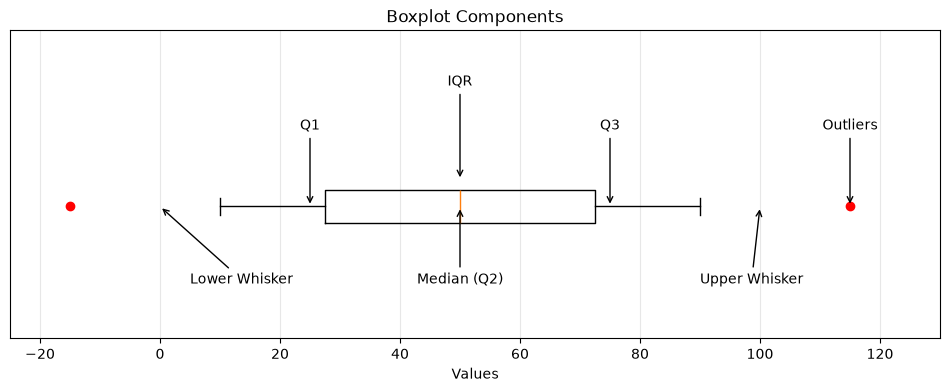

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))


q1 = 25
median = 50
q3 = 75
lower_whisker = 0
upper_whisker = 100
outliers = [-15, 115]


plt.boxplot(
    [[10, 20, 25, 30, 40, 50, 60, 70, 75, 80, 90]],
    vert=False,
    showfliers=False
)


plt.scatter(outliers, [1, 1], color="red", zorder=3)


plt.annotate("Q1", xy=(q1, 1), xytext=(q1, 1.35),
             arrowprops=dict(arrowstyle="->"), ha="center")

plt.annotate("Median (Q2)", xy=(median, 1), xytext=(median, 0.65),
             arrowprops=dict(arrowstyle="->"), ha="center")

plt.annotate("Q3", xy=(q3, 1), xytext=(q3, 1.35),
             arrowprops=dict(arrowstyle="->"), ha="center")

plt.annotate("Lower Whisker", xy=(lower_whisker, 1),
             xytext=(5, 0.65), arrowprops=dict(arrowstyle="->"))

plt.annotate("Upper Whisker", xy=(upper_whisker, 1),
             xytext=(90, 0.65), arrowprops=dict(arrowstyle="->"))

plt.annotate("IQR", xy=(50, 1.12), xytext=(50, 1.55),
             arrowprops=dict(arrowstyle="->"), ha="center")

plt.annotate("Outliers", xy=(115, 1), xytext=(115, 1.35),
             arrowprops=dict(arrowstyle="->"), ha="center")

plt.xlim(-25, 130)
plt.ylim(0.4, 1.8)
plt.yticks([])
plt.title("Boxplot Components")
plt.xlabel("Values")
plt.grid(axis="x", alpha=0.3)

plt.show()

<div dir="rtl" style="text-align: right">

---

### Question 16
با Boxplot و IQR، Outlierهای هر ویژگی عددی را پیدا کنید.

**چرایی پرسش:** خریدهای خیلی بزرگ یا قیمت‌های غیرعادی را شناسایی می‌کنیم.

</div>

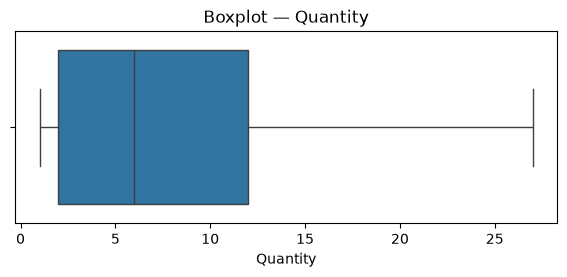

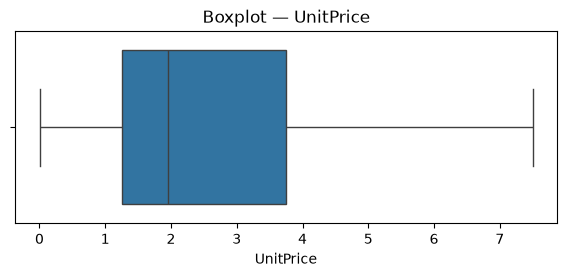

{'Quantity': 0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Name: Quantity, Length: 391151, dtype: bool, 'UnitPrice': 0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Name: UnitPrice, Length: 391151, dtype: bool}


In [36]:
numeric_features = ["Quantity", "UnitPrice"]

for col in numeric_features:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=valid_df[col], showfliers=False)
    plt.title(f"Boxplot — {col}")
    plt.show()
    
outlier_masks = {}

for col in numeric_features:
    q1 = valid_df[col].quantile(0.25)
    q3 = valid_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_masks[col] = (valid_df[col] < lower) | (valid_df[col] > upper)

print(outlier_masks)

<div dir="rtl" style="text-align: right">

---

### Question 17
جدول | Feature | Number of Outliers | را ایجاد کنید.

**چرایی پرسش:** تصمیم درباره Outlier باید بر اساس عدد مستند شود.

</div>

In [45]:
outlier_summary = pd.DataFrame({
    "Feature": numeric_features,
    "Number of Outliers": [int(outlier_masks[c].sum()) for c in numeric_features]
}).sort_values("Number of Outliers", ascending=False)

print(outlier_summary)

     Feature  Number of Outliers
1  UnitPrice               32781
0   Quantity               25593


<div dir="rtl" style="text-align: right">

---

### Question 18
برای Outlierها سه استراتژی مختلف پیشنهاد دهید.

**چرایی پرسش:** حذف کورکورانه عمده‌خریداران ارزشمند به سود شرکت نیست.



### روش‌های مدیریت داده‌های پرت (Outliers)

| Strategy | Pros | Cons |
|---|---|---|
| **حذف (Removal)** | ایجاد داده‌های تمیزتر | احتمال حذف مشتریان ارزشمند |
| **محدودسازی (Capping)** | کنترل مقادیر بسیار بزرگ یا کوچک | حدود باید فقط از داده‌های آموزشی محاسبه شوند |
| **نگه‌داشتن + تبدیل لگاریتمی (Log Transformation)** | بدون حذف داده و کاهش تأثیر مقادیر شدید | تفسیر داده‌ها کمی دشوارتر می‌شود |

**پیشنهاد:** در پروژه پیش‌بینی ریزش مشتری، حذف خودکار داده‌های پرت مناسب نیست؛ چون ممکن است مشتریان باارزش یا سفارش‌های بزرگ را حذف کند. بهتر است ابتدا داده‌های پرت بررسی شوند و در صورت نیاز از روش‌هایی مانند Capping یا تبدیل لگاریتمی استفاده شود.

</div>

<div dir="rtl" style="text-align: right">

---

### Question 19
یک استراتژی را انتخاب و پیاده‌سازی کنید.

**جواب:** نگه‌داشتن و تبدیل لگاریتمی. اینجا اثر آن روی چولگی دیده می‌شود و اجرای کامل روی ویژگی‌ها در Question 42 است.

**چرایی پرسش:** Outlier بدون حذف مشتریان ارزشمند کنترل می‌شود.

</div>

In [46]:
print("Skew before:", round(valid_df["Quantity"].skew(), 2))
print("Skew after :", round(np.log1p(valid_df["Quantity"]).skew(), 2))

Skew before: 406.82
Skew after : 0.82


<div dir="rtl" style="text-align: right">

---

## بخش ۳: Data Construction

### Question 20
برچسب ریزش و تاریخ‌های مرجع را چگونه تعریف می‌کنید؟

**جواب:** تاریخ‌های مرجع: 1 ژوئن، 1 ژوئیه، 1 اوت و 1 سپتامبر 2011. ویژگی‌ها فقط از 180 روز قبل از هر تاریخ مرجع ساخته می‌شوند. اگر مشتری در 90 روز بعد از تاریخ مرجع هیچ خرید معتبری نداشته باشد، `churn = 1`. فقط مشتریانی وارد می‌شوند که در پنجره 180 روزه خرید معتبر داشته‌اند. اطلاعات آینده فقط برای برچسب استفاده می‌شود.

**چرایی پرسش:** دیتاست برچسب ریزش ندارد و این برچسب برای بخش مکمل (Classification) لازم است.

---

### Question 21
حداقل ۱۵ ویژگی رفتاری (LRFM، روند، تنوع و لغو) بسازید.

**چرایی پرسش:** ویژگی‌ها هم ورودی خوشه‌بندی‌اند و هم ورودی مدل طبقه‌بندی.

</div>

In [32]:
ref_dates = ["2011-06-01", "2011-07-01", "2011-08-01", "2011-09-01"]

valid_df["InvoiceDate"] = pd.to_datetime(valid_df["InvoiceDate"])
cancel_df["InvoiceDate"] = pd.to_datetime(cancel_df["InvoiceDate"])

def build_dataset(ref_date_str):
    ref = pd.Timestamp(ref_date_str)
    start = ref - pd.Timedelta(days=180)
    end = ref + pd.Timedelta(days=90)
    mid = ref - pd.Timedelta(days=90)

    past_all = valid_df[valid_df["InvoiceDate"] < ref]
    win = past_all[past_all["InvoiceDate"] >= start].copy()
    win_cancel = cancel_df[(cancel_df["InvoiceDate"] < ref) & (cancel_df["InvoiceDate"] >= start)]
    assert win["InvoiceDate"].max() < ref

    win["line_value"] = win["Quantity"] * win["UnitPrice"]
    win["day"] = win["InvoiceDate"].dt.normalize()
    win["is_uk"] = (win["Country"] == "United Kingdom").astype(int)

    g = win.groupby("CustomerID")
    feat = pd.DataFrame(index=g.size().index)

    feat["recency_days"] = (ref - g["InvoiceDate"].max()).dt.days
    feat["frequency"] = g["InvoiceNo"].nunique()
    feat["monetary"] = g["line_value"].sum()

    feat["avg_order_value"] = feat["monetary"] / feat["frequency"]
    feat["n_unique_products"] = g["StockCode"].nunique()
    feat["n_active_days"] = g["day"].nunique()
    feat["total_items"] = g["Quantity"].sum()
    feat["avg_items_per_order"] = feat["total_items"] / feat["frequency"]

    feat["span_days"] = (g["InvoiceDate"].max() - g["InvoiceDate"].min()).dt.days
    gap = feat["span_days"] / (feat["frequency"] - 1).replace(0, np.nan)
    feat["avg_gap_days"] = gap.fillna(180)
    first_purchase = past_all.groupby("CustomerID")["InvoiceDate"].min()
    feat["tenure_days"] = (ref - first_purchase.reindex(feat.index)).dt.days

    recent = win[win["InvoiceDate"] >= mid]
    prev = win[win["InvoiceDate"] < mid]
    feat["freq_recent90"] = recent.groupby("CustomerID")["InvoiceNo"].nunique()
    feat["freq_prev90"] = prev.groupby("CustomerID")["InvoiceNo"].nunique()
    feat["spend_recent90"] = recent.groupby("CustomerID")["line_value"].sum()
    feat["spend_prev90"] = prev.groupby("CustomerID")["line_value"].sum()
    for c in ["freq_recent90", "freq_prev90", "spend_recent90", "spend_prev90"]:
        feat[c] = feat[c].fillna(0)
    feat["freq_change"] = feat["freq_recent90"] - feat["freq_prev90"]
    feat["spend_change"] = feat["spend_recent90"] - feat["spend_prev90"]

    feat["n_cancel_invoices"] = win_cancel.groupby("CustomerID")["InvoiceNo"].nunique()
    feat["n_cancel_invoices"] = feat["n_cancel_invoices"].fillna(0)
    feat["cancel_rate"] = feat["n_cancel_invoices"] / (feat["n_cancel_invoices"] + feat["frequency"])
    feat["is_uk"] = g["is_uk"].max()

    future = valid_df[(valid_df["InvoiceDate"] >= ref) & (valid_df["InvoiceDate"] < end)]
    future_buyers = set(future["CustomerID"].unique())
    feat["churn"] = (~feat.index.isin(future_buyers)).astype(int)
    feat["ref_date"] = ref
    return feat.reset_index()

dataset = pd.concat([build_dataset(d) for d in ref_dates], ignore_index=True)
print(dataset.shape)
print(dataset.head())

(10914, 23)
   CustomerID  recency_days  frequency  monetary  avg_order_value  \
0     12346.0           133          1  77183.60       77183.6000   
1     12347.0            54          3   1823.43         607.8100   
2     12348.0            56          3   1167.24         389.0800   
3     12350.0           118          1    294.40         294.4000   
4     12352.0            70          4    641.51         160.3775   

   n_unique_products  n_active_days  total_items  avg_items_per_order  \
0                  1              1        74215         74215.000000   
1                 63              3         1117           372.333333   
2                 21              3         2116           705.333333   
3                 16              1          196           196.000000   
4                 24              4          249            62.250000   

   span_days  ...  freq_prev90  spend_recent90  spend_prev90  freq_change  \
0          0  ...          1.0            0.00      77183

<div dir="rtl" style="text-align: right">

---

### Question 22
برای هر ویژگی توضیح دهید چگونه محاسبه شده، چه مفهومی دارد و آیا احتمال نشت اطلاعات دارد.

**چرایی پرسش:** پروژه صراحتاً توضیح هر ویژگی و ریسک نشت آن را می‌خواهد.



## مستندات ویژگی‌های استخراج‌شده (Feature Engineering)

| ویژگی (Feature) | نحوه محاسبه (How It Is Calculated) | مفهوم (Meaning) | خطر نشت داده (Leakage Risk) |
|---|---|---|---|
| `recency_days` | فاصله زمانی آخرین خرید تا تاریخ مرجع | تازگی خرید | ندارد |
| `frequency` | تعداد فاکتورهای معتبر در بازه ۱۸۰ روزه | وفاداری مشتری | ندارد |
| `monetary` | مجموع حاصل‌ضرب تعداد در قیمت خریدهای معتبر | ارزش مالی مشتری | ندارد |
| `avg_order_value` | تقسیم Monetary بر Frequency | میانگین ارزش هر سفارش | ندارد |
| `n_unique_products` | تعداد کدهای محصول یکتا (`StockCode`) | تنوع محصولات خریداری‌شده | ندارد |
| `n_active_days` | تعداد روزهای دارای خرید | پراکندگی فعالیت خرید | ندارد |
| `total_items` | مجموع تعداد اقلام خریداری‌شده | حجم خرید | ندارد |
| `avg_items_per_order` | تقسیم Total Items بر Frequency | میانگین تعداد اقلام در هر سفارش | ندارد |
| `span_days` | فاصله اولین تا آخرین خرید در پنجره زمانی | مدت فعالیت | ندارد |
| `avg_gap_days` | تقسیم Span Days بر (Frequency - 1) | فاصله میانگین بین خریدها | ندارد |
| `tenure_days` | فاصله اولین خرید تاریخی تا تاریخ مرجع | سابقه مشتری (Length) | ندارد |
| `freq_recent90 / freq_prev90 / freq_change` | تعداد فاکتورهای ۹۰ روز اخیر، ۹۰ روز قبل و اختلاف آن‌ها | روند تغییر تعداد خرید | ندارد |
| `spend_recent90 / spend_prev90 / spend_change` | مجموع هزینه ۹۰ روز اخیر، ۹۰ روز قبل و اختلاف آن‌ها | روند تغییر هزینه | ندارد |
| `n_cancel_invoices / cancel_rate` | تعداد فاکتورهای لغوشده پیش از تاریخ مرجع و نسبت آن‌ها به کل فاکتورها | احتمال نارضایتی مشتری | فاکتورهای لغوشده پس از تاریخ مرجع وارد محاسبات نمی‌شوند |
| `is_uk` | مقدار ۱ در صورت بریتانیایی بودن کشور مشتری | بررسی تفاوت بازارها | ندارد |

</div>

<div dir="rtl" style="text-align: right">

---

### Question 23
توزیع برچسب ریزش را در هر تاریخ مرجع بررسی کنید.

**چرایی پرسش:** عدم‌توازن کلاس‌ها و پایداری برچسب در زمان را می‌بینیم.



ref_date = reference date = تاریخ مرجع
</div>

            count      mean
ref_date                   
2011-06-01   2658  0.500376
2011-07-01   2722  0.483835
2011-08-01   2766  0.443239
2011-09-01   2768  0.393064


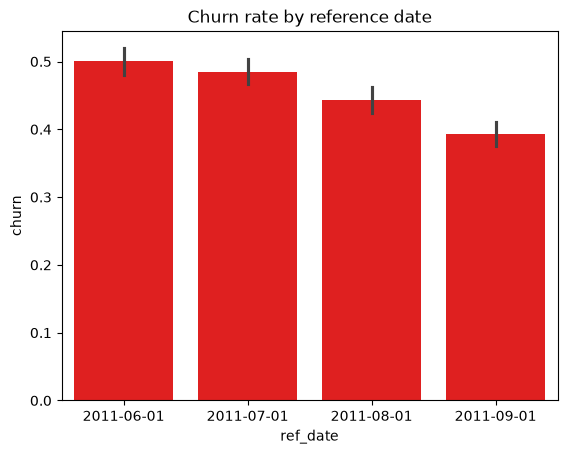

In [52]:
print(dataset.groupby("ref_date")["churn"].agg(["count", "mean"]))

sns.barplot(
    data=dataset,
    x="ref_date", 
    y="churn",
    color="red",
    )
plt.title("Churn rate by reference date")
plt.show()

<div dir="rtl" style="text-align: right">

---

### Question 24
یک ویژگی دسته‌ای برای Recency بسازید (`recency_group`).

**چرایی پرسش:** گروه‌های ساده برای مدیر و بازاریابی قابل‌فهم‌ترند.


یعنی مقدار عددی recency_days را به چند گروه دسته‌بندی کنی؛ مثلاً:
- Recent: خرید در ۳۰ روز اخیر
- Medium: خرید بین ۳۰ تا ۹۰ روز قبل
- Old: خرید بیش از ۹۰ روز قبل

در واقع به‌جای اینکه فاصله آخرین خرید را فقط با عدد نشان بدهی، آن را به گروه‌های قابل‌فهم تبدیل می‌کنی.


</div>

In [33]:
bins = [-1, 30, 90, 181]
dataset[
    "recency_group"] = pd.cut(dataset["recency_days"], bins=bins,
    labels=["Active", "Cooling", "Dormant"]
    )
print(dataset["recency_group"].value_counts())

recency_group
Cooling    3965
Active     3948
Dormant    3001
Name: count, dtype: int64


<div dir="rtl" style="text-align: right">

---

### Question 25
یک ویژگی دسته‌ای برای Frequency بسازید (`frequency_group`).

**چرایی پرسش:** مشتری یک‌بار خرید و مشتری وفادار اقدام‌های متفاوتی می‌خواهند.



یعنی مشتری‌ها را بر اساس تعداد دفعات خرید (frequency) به چند گروه تقسیم کنی؛ مثلاً:
- Low: خرید کم (۱ تا ۲ فاکتور)
- Medium: خرید متوسط (۳ تا ۵ فاکتور)
- High: خرید زیاد (بیش از ۵ فاکتور)

هدف این است که مشتریان کم‌خرید را از مشتریان پرتکرار و وفادار تشخیص بدهی تا بتوان برای هر گروه راهکار متفاوتی در نظر گرفت.


</div>

In [55]:
bins = [0, 1, 3, np.inf]
dataset[
    "frequency_group"] = pd.cut(dataset["frequency"], bins=bins,
    labels=["One-time", "Occasional", "Loyal"]
    )
print(dataset["frequency_group"].value_counts())

frequency_group
One-time      5182
Occasional    3556
Loyal         2176
Name: count, dtype: int64


<div dir="rtl" style="text-align: right">

---

### Question 26
جدول | New Feature | Business Reason | را تکمیل کنید.

**چرایی پرسش:** هر ویژگی ساخته‌شده باید پشتوانه کسب‌وکاری داشته باشد.


### ویژگی‌های جدید و دلیل استفاده از آن‌ها

| ویژگی جدید (New Feature) | دلیل کسب‌وکاری (Business Reason) |
|---|---|
| `recency_group` | بازاریابی می‌تواند هر گروه از مشتریان را به یک اقدام مشخص متصل کند. |
| `frequency_group` | تفکیک مشتریانی که فقط یک‌بار خرید کرده‌اند از مشتریان وفادار |
| `cancel_rate` | نشانه‌ای احتمالی از نارضایتی مشتری |
| `freq_change / spend_change` | کاهش تدریجی تعداد خرید یا هزینه معمولاً پیش از ریزش کامل رخ می‌دهد. |
| `tenure_days` | نشان‌دهنده قدمت و سابقه مشتری (Length در مدل LRFM) |


</div>

In [56]:
new_features = pd.DataFrame({
    "New Feature": [
        "recency_group", "frequency_group", "cancel_rate",
        "freq_change / spend_change", "tenure_days"
        ],
    "Business Reason": [
        "بازاریابی راحت‌تر می‌تواند هر گروه را به یک اقدام وصل کند",
        "تفکیک مشتری یک‌بار خرید از مشتری وفادار",
        "نشانه احتمالی نارضایتی",
        "کاهش تدریجی خرید معمولاً پیش از ریزش کامل رخ می‌دهد",
        "قدمت مشتری (Length در LRFM)"
        ]
})
print(new_features)

                  New Feature  \
0               recency_group   
1             frequency_group   
2                 cancel_rate   
3  freq_change / spend_change   
4                 tenure_days   

                                     Business Reason  
0  بازاریابی راحت‌تر می‌تواند هر گروه را به یک اق...  
1            تفکیک مشتری یک‌بار خرید از مشتری وفادار  
2                             نشانه احتمالی نارضایتی  
3  کاهش تدریجی خرید معمولاً پیش از ریزش کامل رخ م...  
4                        قدمت مشتری (Length در LRFM)  


<div dir="rtl" style="text-align: right">

---

## بخش ۴: Data Integration


### Question 27
یک DataFrame آزمایشی برای فایل CRM بسازید.

**چرایی پرسش:** در پروژه واقعی داده از چند منبع می‌آید.

</div>

In [61]:
base = dataset[dataset["ref_date"] == "2011-06-01"]
ids = base["CustomerID"].head(3).tolist()

crm = pd.DataFrame({
    "CustomerID": ids + [99999],
    "email_opt_in": [1, 0, 1, 1],
    "signup_channel": ["web", "app", "web", "app"]
})
print(crm)

   CustomerID  email_opt_in signup_channel
0     12346.0             1            web
1     12347.0             0            app
2     12348.0             1            web
3     99999.0             1            app


<div dir="rtl" style="text-align: right">

---

### Question 28
یک کلید مشترک تعریف کنید.

**جواب:** `CustomerID`.

**چرایی پرسش:** کلید مشترک تعیین می‌کند دو جدول به چه ترتیبی به هم وصل شوند.

</div>

In [58]:
print("Common key:", "CustomerID")
print(set(base.columns) & set(crm.columns))

Common key: CustomerID
{'CustomerID'}


<div dir="rtl" style="text-align: right">

---

### Question 29
Merge را انجام دهید.

**چرایی پرسش:** اطلاعات CRM به داده مشتری اضافه می‌شود.

</div>

In [59]:
base_demo = pd.DataFrame({
    "CustomerID": [12346, 12347, 12348],
    "recency_days": [10, 45, 80],
    "frequency": [5, 3, 1]
})

merged_df = base_demo.merge(
    crm,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

print(merged_df[["CustomerID", "email_opt_in", "signup_channel"]].head())

   CustomerID  email_opt_in signup_channel
0       12346             1            web
1       12347             0            app
2       12348             1            web


<div dir="rtl" style="text-align: right">

---

### Question 30
انواع Merge (inner، left، right، outer) را مقایسه کنید.

**چرایی پرسش:** نوع Merge تعیین می‌کند چه سطرهایی می‌مانند.


یعنی تفاوت چهار نوع ادغام دیتافریم‌ها (Merge) را توضیح بدهی و مشخص کنی هرکدام چه رکوردهایی را نگه می‌دارند:
- Inner: فقط رکوردهای مشترک در هر دو جدول.
- Left: تمام رکوردهای جدول سمت چپ، حتی اگر در جدول راست معادل نداشته باشند.
- Right: تمام رکوردهای جدول سمت راست.
- Outer: تمام رکوردهای هر دو جدول، چه مشترک باشند چه نباشند.

</div>

In [63]:
for how in ["inner", "left", "right", "outer"]:
    print(how, "->", base.merge(crm, on="CustomerID", how=how).shape)

inner -> (3, 27)
left -> (2658, 27)
right -> (4, 27)
outer -> (2659, 27)


<div dir="rtl" style="text-align: right">

---

### Question 31
برای این پروژه کدام نوع Merge مناسب‌تر است؟

**جواب:** `left`. هدف ما مشتریانی است که تراکنش دارند و نباید مشتری را به‌خاطر نبود اطلاعات CRM از دست بدهیم. مقدارهای گمشده CRM با «نامشخص» پر می‌شود.

**چرایی پرسش:** انتخاب باید با هدف پروژه هماهنگ باشد.

---

## بخش ۵: Data Formatting

### Question 32
نوع داده تمامی ستون‌ها را بررسی کنید.

**چرایی پرسش:** نوع نامناسب (مثل CustomerID اعشاری) باید اصلاح شود.

</div>

In [35]:
print(dataset.dtypes)
print(dataset.info())

CustomerID                    float64
recency_days                    int64
frequency                       int64
monetary                      float64
avg_order_value               float64
n_unique_products               int64
n_active_days                   int64
total_items                     int64
avg_items_per_order           float64
span_days                       int64
avg_gap_days                  float64
tenure_days                     int64
freq_recent90                 float64
freq_prev90                   float64
spend_recent90                float64
spend_prev90                  float64
freq_change                   float64
spend_change                  float64
n_cancel_invoices             float64
cancel_rate                   float64
is_uk                           int64
churn                           int64
ref_date               datetime64[us]
recency_group                category
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 10914 entries, 0 to 10913
Data colu

<div dir="rtl" style="text-align: right">

---

### Question 33
ستون‌هایی که باید Category باشند را شناسایی کنید.

**چرایی پرسش:** نوع Category حافظه را کم می‌کند و مقایسه را درست می‌کند.

</div>

In [38]:
category_cols = ["recency_group", "frequency_group"]
print(category_cols)

['recency_group', 'frequency_group']


<div dir="rtl" style="text-align: right">

---

### Question 34
Datatype مناسب را اعمال کنید.

**چرایی پرسش:** از خطای نوع جلوگیری می‌کنیم.

</div>